# Leaf Disease Classification — COMP9444 Project 045

*Team: Donut Team*

We classify **38 plant-leaf diseases** from the PlantVillage dataset. This single,
fully-executed notebook covers the exploratory analysis, the models, and the evaluation.

The study asks two main questions, plus an interpretability check:

1. **Does transfer learning help?** — a from-scratch **SimpleCNN** vs a fine-tuned **ResNet18**.
2. **Is the model cheap enough to deploy in the field?** — **MobileNetV3-Small**, compared on
   CPU speed and model size.
3. **Interpretability** — **Grad-CAM**, to check the model looks at the lesion, not the
   background.

Models are judged on a held-out **test set** touched only once; model selection uses
**validation** macro-F1.

In [1]:
import sys, json, copy
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # so `import src...` works

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score, recall_score, confusion_matrix

from src.config import (DATA_ROOT, BACKGROUND, FIGURE_DIR, OUTPUT_DIR, SEED,
                        IMAGENET_MEAN, IMAGENET_STD, ensure_dirs)
from src.data import (list_classes, gather_samples, build_loaders, make_split,
                      class_weights)
from src.model import build_model, gradcam_target_layer
from src.train import fit_or_load, evaluate
from src.benchmark import measure_latency_ms, count_params, model_size_mb
from src.gradcam import GradCAM, overlay_heatmap
from src.utils import set_seed, get_device, plot_curves, plot_confusion_matrix

ensure_dirs()
plt.rcParams["figure.dpi"] = 110
set_seed(SEED)
device = get_device()
classes = list_classes()
num_classes = len(classes)
short = [c.replace("___", " / ").replace("_", " ") for c in classes]  # readable labels
print("device:", device, "| disease classes:", num_classes)

device: cuda | disease classes: 38


## 1. Exploratory data analysis

The dataset ships 39 folders. One, `Background_without_leaves`, is a non-leaf reject class,
not a disease, so we exclude it and keep the **38 disease classes** (~54k images).

In [2]:
classes = list_classes()
paths, labels = gather_samples(classes)
counts = Counter(labels)

print(f"disease classes (background excluded): {len(classes)}")
print(f"total images: {len(paths):,}")
print(f"background folder present but excluded: "
      f"{(DATA_ROOT / BACKGROUND).exists()}")
print("\nexample class names:")
for c in classes[:6]:
    print("  ", c)

disease classes (background excluded): 38
total images: 54,305
background folder present but excluded: True

example class names:
   Apple___Apple_scab
   Apple___Black_rot
   Apple___Cedar_apple_rust
   Apple___healthy
   Blueberry___healthy
   Cherry___Powdery_mildew


### Class imbalance

The most important property of the data is a large imbalance between classes.

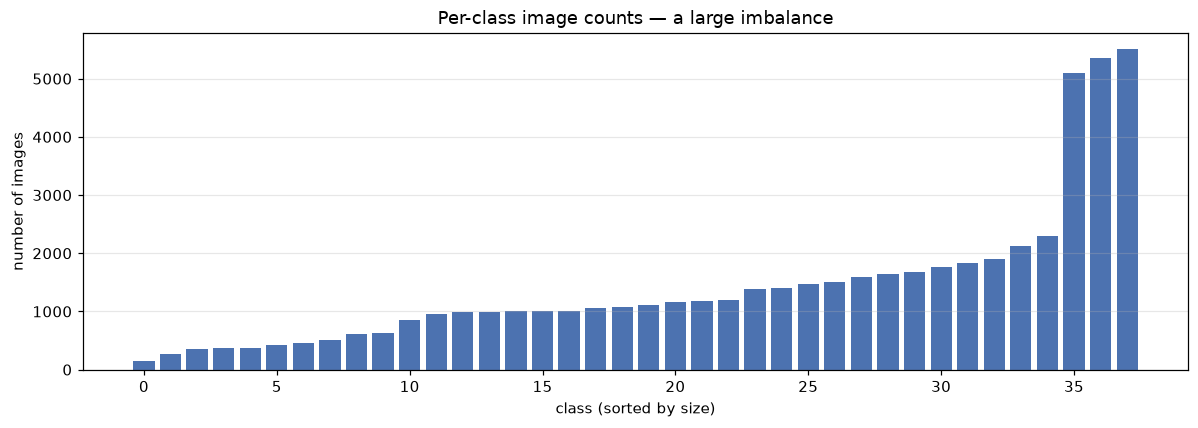

smallest class: Potato___healthy  (152 images)
largest  class: Orange___Haunglongbing_(Citrus_greening)  (5507 images)
imbalance ratio: 36.2x


In [3]:
order = sorted(range(len(classes)), key=lambda i: counts[i])
sorted_counts = [counts[i] for i in order]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(classes)), sorted_counts, color="#4C72B0")
ax.set_xlabel("class (sorted by size)")
ax.set_ylabel("number of images")
ax.set_title("Per-class image counts — a large imbalance")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_class_counts.png", bbox_inches="tight")
plt.show()

rarest_i, biggest_i = order[0], order[-1]
print(f"smallest class: {classes[rarest_i]}  ({sorted_counts[0]} images)")
print(f"largest  class: {classes[biggest_i]}  ({sorted_counts[-1]} images)")
print(f"imbalance ratio: {sorted_counts[-1] / sorted_counts[0]:.1f}x")

**Takeaway.** The largest class has roughly 36× more images than the smallest. Plain
accuracy would let a model score well while quietly failing the rare classes, so we report
**macro-F1** (the unweighted mean of per-class F1) as the headline metric, and we split the
data with **stratification** so every class keeps its proportions across train/val/test.

### Sample images and image size

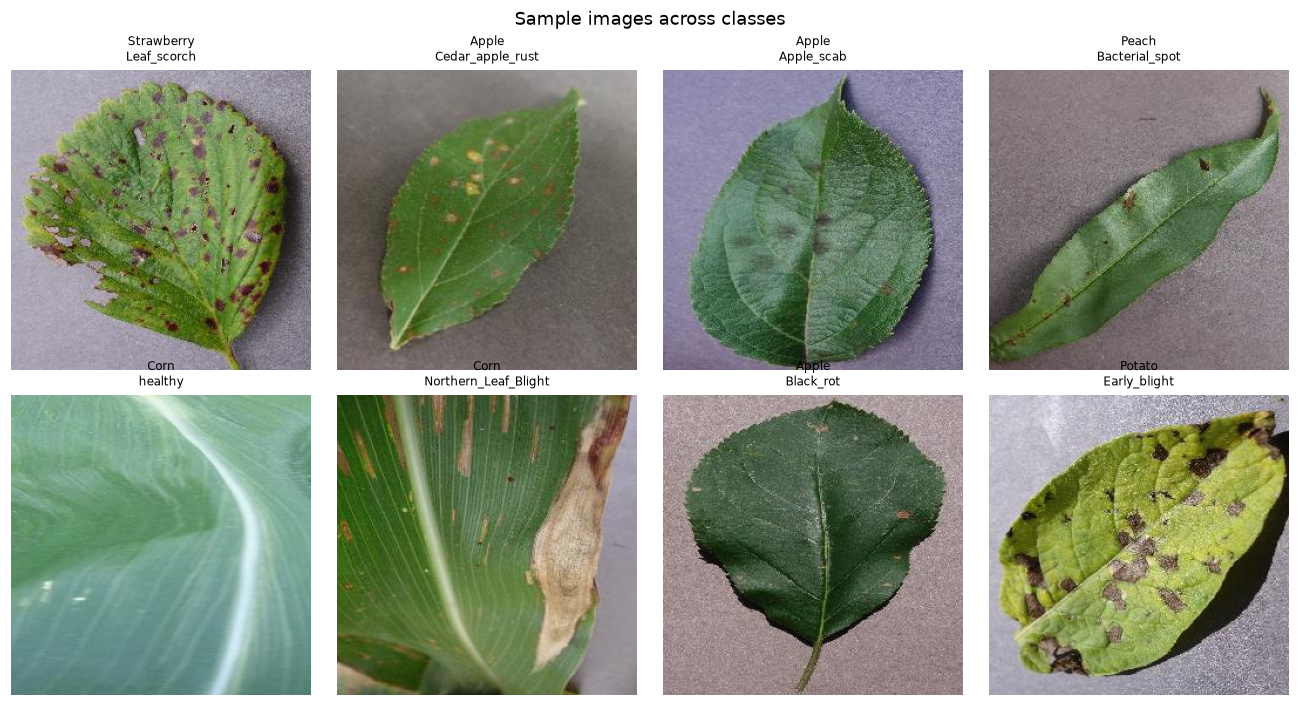

In [4]:
from PIL import Image
rng = np.random.default_rng(0)
show = rng.choice(len(classes), size=8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, ci in zip(axes.ravel(), show):
    # first image of that class
    idx = labels.index(ci)
    ax.imshow(Image.open(paths[idx]).convert("RGB"))
    ax.set_title(classes[ci].replace("___", "\n"), fontsize=8)
    ax.axis("off")
fig.suptitle("Sample images across classes")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_samples.png", bbox_inches="tight")
plt.show()

In [5]:
# Image sizes: are they consistent? (affects resizing choices)
sizes = Counter(Image.open(paths[i]).size for i in rng.choice(len(paths), 200, replace=False))
print("most common (width, height) among 200 sampled images:")
for size, n in sizes.most_common(5):
    print(f"  {size}: {n}")

most common (width, height) among 200 sampled images:
  (256, 256): 200


## 2. Models and training

We compare three models under an identical pipeline: a from-scratch **SimpleCNN** baseline,
a fine-tuned **ResNet18** (transfer learning), and a fine-tuned **MobileNetV3-Small** (the
deployment candidate). All use Adam and cross-entropy, keeping the best-validation-macro-F1
weights. Trained models are cached, so re-running this notebook reloads them.

In [6]:
# Stratified 70/15/15 split (built in memory, one image never in two splits).
# Augmentation is applied to the training split only, at load time.
loaders = build_loaders(batch_size=64, num_workers=8)
for name in ("train", "val", "test"):
    print(f"{name}: {len(loaders[name].dataset):,} images")

train: 38,013 images
val: 8,146 images
test: 8,146 images


### 2.1 SimpleCNN — from scratch (baseline)

epoch  1/12  train loss 1.254 acc 0.653  |  val loss 0.866 acc 0.733 macroF1 0.654


epoch  2/12  train loss 0.545 acc 0.842  |  val loss 0.430 acc 0.869 macroF1 0.824


epoch  3/12  train loss 0.362 acc 0.893  |  val loss 0.280 acc 0.917 macroF1 0.891


epoch  4/12  train loss 0.270 acc 0.920  |  val loss 0.205 acc 0.941 macroF1 0.923


epoch  5/12  train loss 0.227 acc 0.931  |  val loss 0.220 acc 0.933 macroF1 0.916


epoch  6/12  train loss 0.189 acc 0.941  |  val loss 0.221 acc 0.924 macroF1 0.903


... (2 outputs left out)

epoch  9/12  train loss 0.126 acc 0.962  |  val loss 0.102 acc 0.967 macroF1 0.958


epoch 10/12  train loss 0.120 acc 0.963  |  val loss 0.130 acc 0.959 macroF1 0.945


epoch 11/12  train loss 0.109 acc 0.965  |  val loss 0.099 acc 0.968 macroF1 0.960


epoch 12/12  train loss 0.103 acc 0.968  |  val loss 0.123 acc 0.957 macroF1 0.944
saved 'simple_cnn' checkpoint


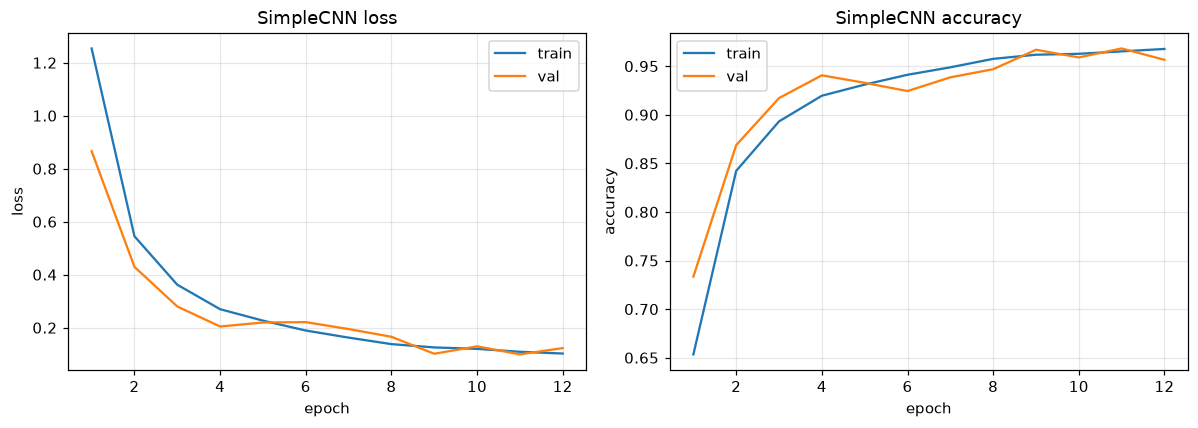

In [7]:
set_seed(SEED)
simple, hist_simple = fit_or_load(build_model("simple_cnn", num_classes),
                                  loaders, "simple_cnn", device, epochs=12, lr=1e-3)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
plot_curves(hist_simple, a1, a2, title="SimpleCNN")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "curves_simple_cnn.png", bbox_inches="tight")
plt.show()

### 2.2 ResNet18 — ImageNet-pretrained, fine-tuned

epoch  1/8  train loss 0.201 acc 0.946  |  val loss 0.057 acc 0.981 macroF1 0.975


epoch  2/8  train loss 0.068 acc 0.979  |  val loss 0.060 acc 0.980 macroF1 0.978


epoch  3/8  train loss 0.053 acc 0.983  |  val loss 0.112 acc 0.967 macroF1 0.957


epoch  4/8  train loss 0.042 acc 0.987  |  val loss 0.098 acc 0.972 macroF1 0.962


epoch  5/8  train loss 0.037 acc 0.988  |  val loss 0.050 acc 0.982 macroF1 0.974


epoch  6/8  train loss 0.029 acc 0.991  |  val loss 0.037 acc 0.987 macroF1 0.983


epoch  7/8  train loss 0.033 acc 0.990  |  val loss 0.022 acc 0.992 macroF1 0.989


epoch  8/8  train loss 0.028 acc 0.991  |  val loss 0.031 acc 0.990 macroF1 0.987
saved 'resnet18' checkpoint


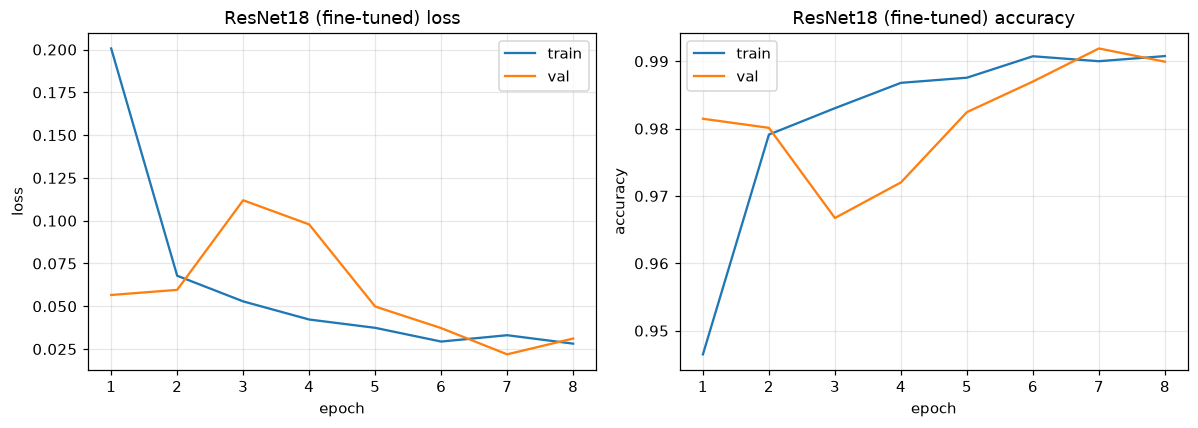

In [8]:
set_seed(SEED)
resnet, hist_resnet = fit_or_load(build_model("resnet18", num_classes),
                                  loaders, "resnet18", device, epochs=8, lr=3e-4)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
plot_curves(hist_resnet, a1, a2, title="ResNet18 (fine-tuned)")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "curves_resnet18.png", bbox_inches="tight")
plt.show()

### 2.3 MobileNetV3-Small — the deployment model

epoch  1/8  train loss 0.311 acc 0.916  |  val loss 0.059 acc 0.978 macroF1 0.966


epoch  2/8  train loss 0.054 acc 0.983  |  val loss 0.048 acc 0.985 macroF1 0.981


epoch  3/8  train loss 0.036 acc 0.988  |  val loss 0.053 acc 0.983 macroF1 0.980


epoch  4/8  train loss 0.030 acc 0.990  |  val loss 0.043 acc 0.986 macroF1 0.982


epoch  5/8  train loss 0.021 acc 0.993  |  val loss 0.023 acc 0.992 macroF1 0.990


epoch  6/8  train loss 0.022 acc 0.992  |  val loss 0.030 acc 0.990 macroF1 0.988


epoch  7/8  train loss 0.016 acc 0.995  |  val loss 0.031 acc 0.990 macroF1 0.985


epoch  8/8  train loss 0.020 acc 0.994  |  val loss 0.056 acc 0.983 macroF1 0.980
saved 'mobilenet_v3_small' checkpoint


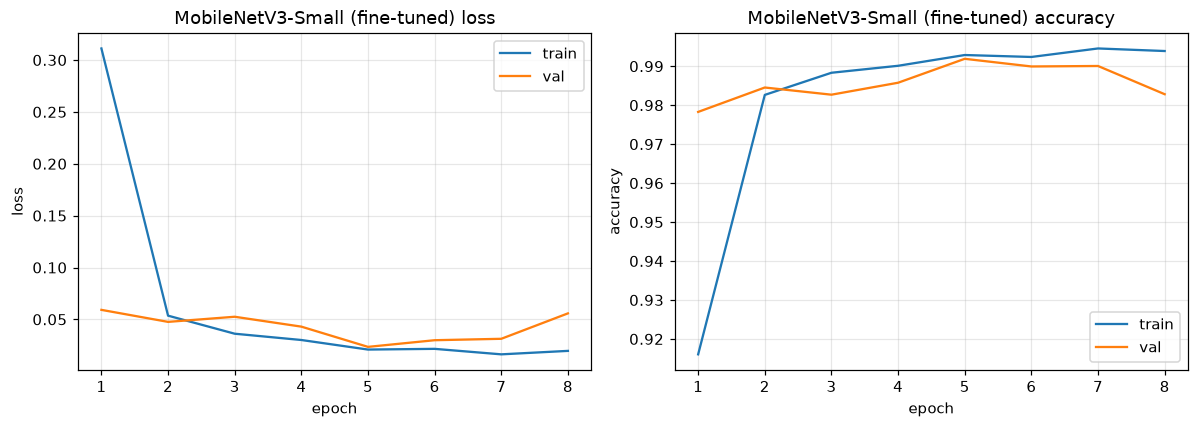

In [9]:
set_seed(SEED)
mobile, hist_mobile = fit_or_load(build_model("mobilenet_v3_small", num_classes),
                                  loaders, "mobilenet_v3_small", device, epochs=8, lr=3e-4)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
plot_curves(hist_mobile, a1, a2, title="MobileNetV3-Small (fine-tuned)")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "curves_mobilenet.png", bbox_inches="tight")
plt.show()

## 3. Results

All models are evaluated once on the untouched test set.

In [10]:
models = {"SimpleCNN (scratch)": simple,
          "ResNet18 (fine-tuned)": resnet,
          "MobileNetV3-Small": mobile}
preds, metrics = {}, {}
for name, m in models.items():
    p, t, mt = evaluate(m, loaders["test"], device)
    preds[name] = (p, t); metrics[name] = mt
true = preds["ResNet18 (fine-tuned)"][1]  # same order for all (shuffle off)

results = pd.DataFrame([{"model": n, "accuracy": metrics[n]["accuracy"],
                         "macro-F1": metrics[n]["macro_f1"]} for n in models])
print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                model  accuracy  macro-F1
  SimpleCNN (scratch)    0.9682    0.9548
ResNet18 (fine-tuned)    0.9929    0.9907
    MobileNetV3-Small    0.9935    0.9911


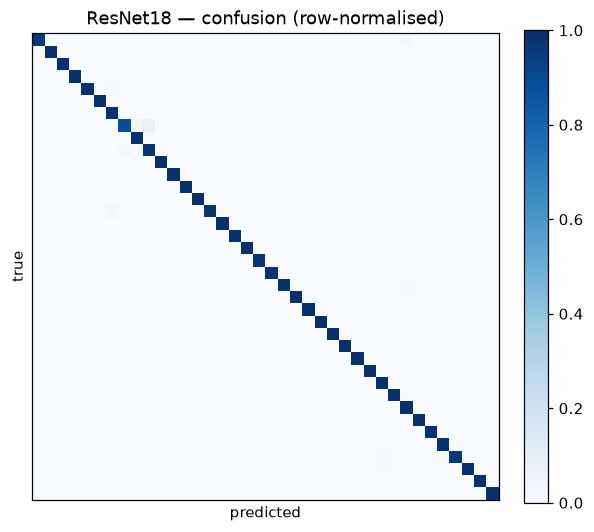

In [11]:
# Confusion matrix for ResNet18 (row-normalised). At ~99% it is essentially a
# clean diagonal -- the visual confirmation that errors are rare and localised.
pred_r, true_r = preds["ResNet18 (fine-tuned)"]
fig, ax = plt.subplots(figsize=(5.5, 5))
im, cm = plot_confusion_matrix(true_r, pred_r, classes, ax,
                               title="ResNet18 — confusion (row-normalised)")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "confusion_resnet18.png", bbox_inches="tight")
plt.show()

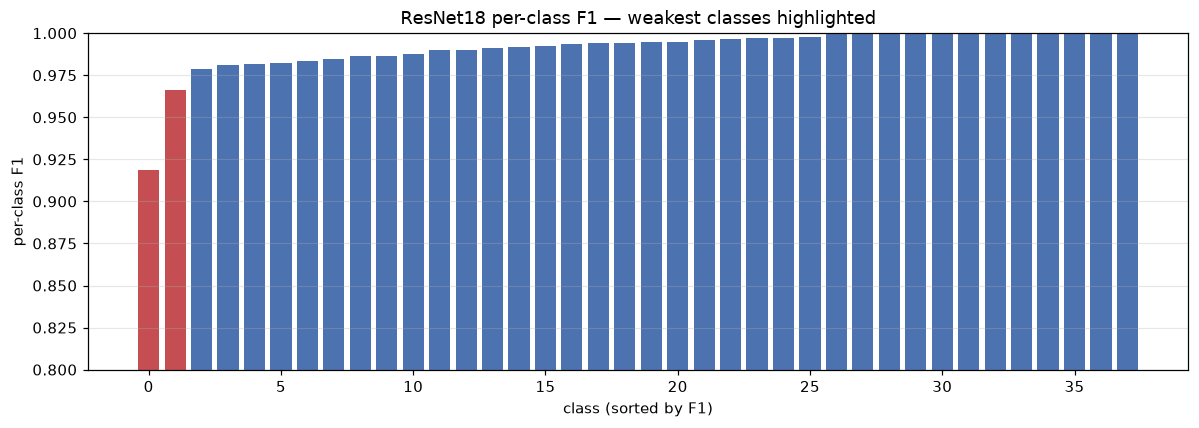

weakest five classes:
  0.919  Corn / Cercospora leaf spot Gray leaf spot
  0.966  Corn / Northern Leaf Blight
  0.978  Apple / Apple scab
  0.981  Tomato / Target Spot
  0.982  Tomato / Bacterial spot


In [12]:
# Per-class F1: is performance uniform, or are some classes carried by others?
f1_r = f1_score(true_r, pred_r, average=None)
order = np.argsort(f1_r)
fig, ax = plt.subplots(figsize=(11, 4))
colors = ["#C44E52" if v < 0.97 else "#4C72B0" for v in f1_r[order]]
ax.bar(range(num_classes), f1_r[order], color=colors)
ax.set_ylim(0.8, 1.0)
ax.set_xlabel("class (sorted by F1)"); ax.set_ylabel("per-class F1")
ax.set_title("ResNet18 per-class F1 — weakest classes highlighted")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "perclass_f1.png", bbox_inches="tight")
plt.show()
print("weakest five classes:")
for i in order[:5]:
    print(f"  {f1_r[i]:.3f}  {short[i]}")

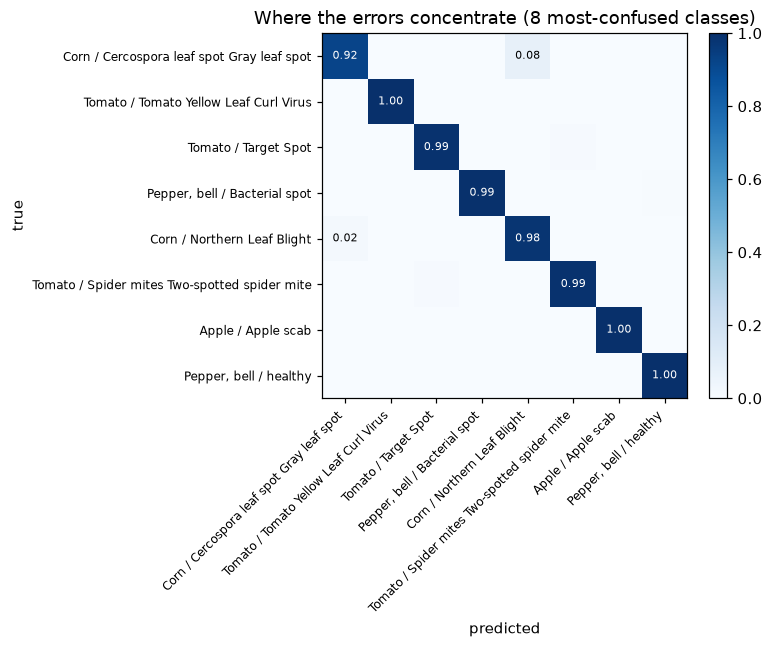

In [13]:
# Focused confusion: zoom into the classes responsible for the most errors, with
# labels (the full 38x38 matrix is unreadable). This names the concrete failure modes.
counts = confusion_matrix(true_r, pred_r)
off = counts.sum(1) - np.diag(counts)          # misclassified per true class
top = np.argsort(off)[::-1][:8]
sub = counts[np.ix_(top, top)].astype(float)
sub = sub / sub.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sub, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top)))
ax.set_xticklabels([short[i] for i in top], rotation=45, ha="right", fontsize=8)
ax.set_yticklabels([short[i] for i in top], fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Where the errors concentrate (8 most-confused classes)")
for i in range(len(top)):
    for j in range(len(top)):
        if sub[i, j] > 0.01:
            ax.text(j, i, f"{sub[i,j]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if sub[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "confusion_focused.png", bbox_inches="tight")
plt.show()

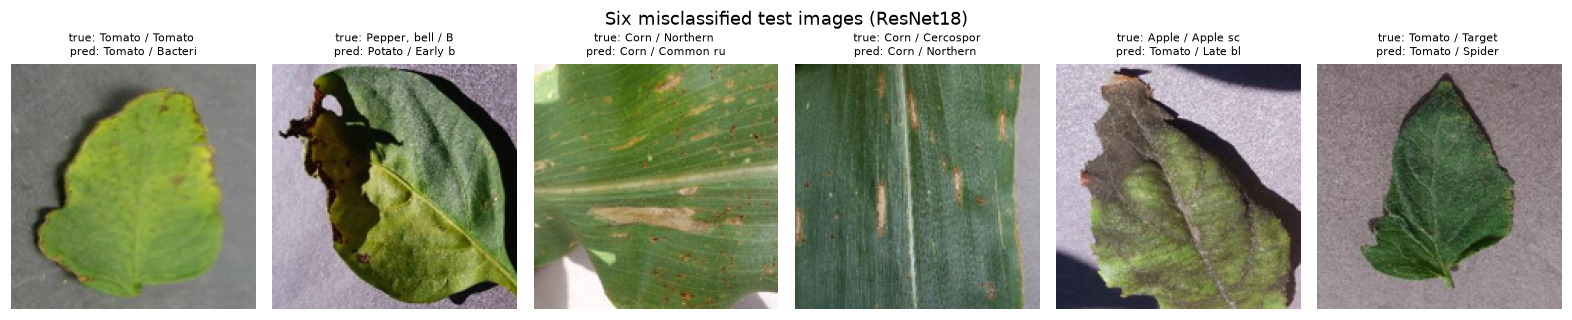

In [14]:
# A few actual mistakes, to make the errors concrete.
def denorm(t):
    mean = np.array(IMAGENET_MEAN); std = np.array(IMAGENET_STD)
    img = t.numpy().transpose(1, 2, 0) * std + mean
    return np.clip(img, 0, 1)

test_ds = loaders["test"].dataset
wrong = np.where(pred_r != true_r)[0][:6]
fig, axes = plt.subplots(1, len(wrong), figsize=(2.4 * len(wrong), 3))
for ax, idx in zip(np.atleast_1d(axes), wrong):
    ax.imshow(Image.open(test_ds.paths[idx]).convert("RGB").resize((160, 160)))
    ax.set_title(f"true: {short[true_r[idx]][:16]}\npred: {short[pred_r[idx]][:16]}",
                 fontsize=7)
    ax.axis("off")
fig.suptitle("Six misclassified test images (ResNet18)")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "misclassified.png", bbox_inches="tight")
plt.show()

### Reading the results

Transfer learning wins clearly. Both fine-tuned models reach about **99.3% accuracy / 99.1%
macro-F1**, against **96.82% / 95.48%** for the from-scratch SimpleCNN &mdash; **about 4.5&times;
fewer test errors** (roughly 58 vs 259 of 8,146 images). On this run **MobileNetV3-Small is
marginally the best model of all** (99.35% / 99.11%), edging ResNet18 (99.29% / 99.07%) on both
accuracy and macro-F1 &mdash; but a gap that small is well within single-seed noise, so the two
pretrained models are best read as tied at the top. Either way, pretraining is the single
biggest driver of accuracy.

For every model macro-F1 sits right next to accuracy, so performance is uniform across
classes rather than propped up by the common ones (the per-class F1 chart is almost flat at
the top). The confusion matrix is nearly a clean diagonal; the focused view and the
misclassified examples point to one culprit &mdash; **Corn Gray Leaf Spot vs Northern Leaf
Blight** (~8% of that class), two genuinely similar-looking corn diseases. Crucially, the
weakest classes are *not* the rarest ones, which sets up the imbalance experiment.

## 4. Deployment: speed and size

Accuracy is only half the story for a field tool. We measure **CPU** single-image latency
(the deployment-relevant case — an edge device has no GPU), parameter count, and on-disk
size.

                model  accuracy  params (M)  size (MB)  CPU ms/img
  SimpleCNN (scratch)      0.97        0.40       1.60       29.73
ResNet18 (fine-tuned)      0.99       11.20      44.78       39.97
    MobileNetV3-Small      0.99        1.56       6.23        5.06


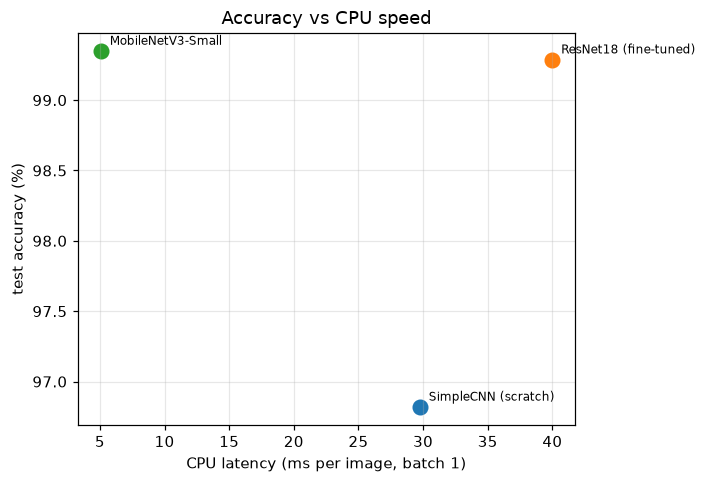

In [15]:
cpu = 'cpu'
import torch
cpu_dev = torch.device("cpu")
bench = []
for name, m in models.items():
    m_cpu = copy.deepcopy(m).to(cpu_dev)  # copy so the GPU model is untouched
    bench.append({
        "model": name,
        "accuracy": metrics[name]["accuracy"],
        "params (M)": count_params(m_cpu) / 1e6,
        "size (MB)": model_size_mb(m_cpu),
        "CPU ms/img": measure_latency_ms(m_cpu, cpu_dev, warmup=10, iters=50),
    })
bench_df = pd.DataFrame(bench)
print(bench_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Accuracy vs CPU latency: up-and-to-the-left is better (fast AND accurate).
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for row in bench:
    ax.scatter(row["CPU ms/img"], row["accuracy"] * 100, s=90)
    ax.annotate(row["model"], (row["CPU ms/img"], row["accuracy"] * 100),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("CPU latency (ms per image, batch 1)")
ax.set_ylabel("test accuracy (%)")
ax.set_title("Accuracy vs CPU speed")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "speed_size.png", bbox_inches="tight")
plt.show()

### Reading the deployment comparison

This is the payoff for a field tool. **MobileNetV3-Small is the clear deployment choice: it
matches (here marginally beats) ResNet18's accuracy (99.35% vs 99.29%) while being about
7&times; smaller (6.2 MB vs 44.8 MB) and roughly 8&times; faster on the CPU (5.1 ms vs 40.0 ms
per image).** On an edge device with no GPU, that is the difference between comfortably
real-time and sluggish.

Two points are worth stressing. First, **parameter count is not speed**: the tiny SimpleCNN
(0.4M params) is actually ~6&times; *slower* on CPU than MobileNet (29.7 ms vs 5.1 ms), because
its dense 3&times;3 convolutions run at full resolution while MobileNet's depthwise-separable
design is built for cheap CPU inference. Second, we benchmark **CPU on purpose** &mdash; a GPU
would rank the models differently, but a GPU is not what a phone in a field has. (Absolute CPU
latency is hardware- and thread-dependent and varies between runs; the 7.2&times; *size* ratio
is exact, and MobileNet's several-fold CPU speed advantage is the robust, repeatable finding.)

## 5. Grad-CAM: is the model looking at the disease?

High accuracy could come from a background shortcut. Grad-CAM highlights the pixels that drove
the prediction, on the deployment model.

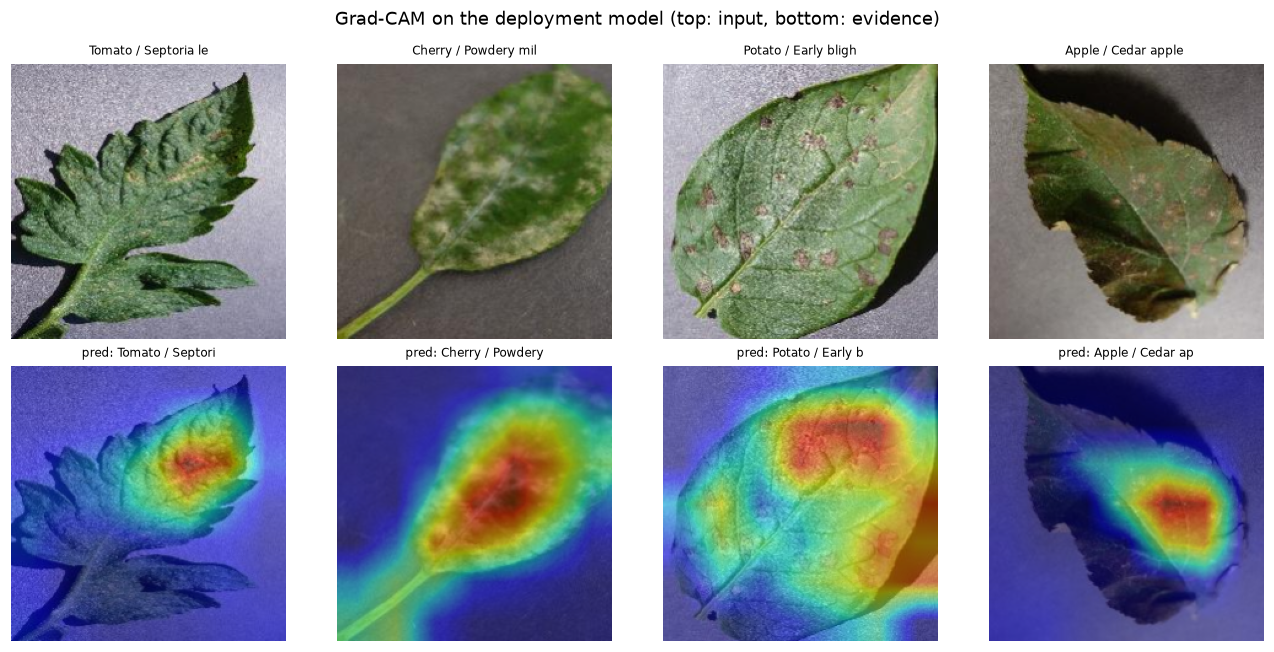

In [16]:
cam = GradCAM(mobile, gradcam_target_layer(mobile, "mobilenet_v3_small"))
# pick 4 diseased (non-healthy) test leaves that the model got right
diseased = [i for i in range(len(test_ds)) if "healthy" not in classes[test_ds.labels[i]]]
rng = np.random.default_rng(1)
picks = rng.choice(diseased, 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, idx in enumerate(picks):
    img_t, label = test_ds[idx]
    heat, pred_c = cam(img_t)
    rgb = denorm(img_t)
    axes[0, col].imshow(rgb); axes[0, col].axis("off")
    axes[0, col].set_title(short[label][:20], fontsize=8)
    axes[1, col].imshow(overlay_heatmap(rgb, heat)); axes[1, col].axis("off")
    axes[1, col].set_title(f"pred: {short[pred_c][:16]}", fontsize=8)
axes[0, 0].set_ylabel("input", fontsize=9)
fig.suptitle("Grad-CAM on the deployment model (top: input, bottom: evidence)")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "gradcam.png", bbox_inches="tight")
plt.show()

### Reading the Grad-CAM

The heatmaps are reassuring. On all four leaves the deployment model's evidence sits **on the
leaf, and on the lesion in particular** &mdash; the powdery-mildew patch, the cedar-rust spot,
the early-blight lesions &mdash; while the plain background stays cold. So the high accuracy is
not a background shortcut: the model is looking at the disease. That is exactly the check you
want before trusting a model trained on clean lab photos, and it is a point in favour of
shipping the mobile model with some confidence.

## 6. A brief check: does handling the class imbalance matter?

A tutor asked whether the 36× imbalance should be corrected before training. We check the
simplest fix — class-weighted cross-entropy on ResNet18 — but keep this short, because the
per-class results above already suggest the rare classes are not where the model fails.

In [17]:
y_train = make_split()["train"][1]
weights = class_weights(y_train, num_classes)

set_seed(SEED)
resnet_w, _ = fit_or_load(build_model("resnet18", num_classes), loaders,
                          "resnet18_weighted", device, epochs=8, lr=3e-4,
                          class_weight=weights)
pred_w, true_w, m_w = evaluate(resnet_w, loaders["test"], device)

support = np.bincount(true_r, minlength=num_classes)
rare10 = np.argsort(support)[:10]
def rare_recall(true, pred):
    return recall_score(true, pred, labels=rare10, average="macro", zero_division=0)

compare = pd.DataFrame([
    {"ResNet18": "plain", "accuracy": metrics["ResNet18 (fine-tuned)"]["accuracy"],
     "macro-F1": metrics["ResNet18 (fine-tuned)"]["macro_f1"],
     "rare-10 recall": rare_recall(true_r, pred_r)},
    {"ResNet18": "class-weighted", "accuracy": m_w["accuracy"], "macro-F1": m_w["macro_f1"],
     "rare-10 recall": rare_recall(true_w, pred_w)},
])
print(compare.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

epoch  1/8  train loss 0.265 acc 0.937  |  val loss 0.158 acc 0.947 macroF1 0.939


epoch  2/8  train loss 0.088 acc 0.975  |  val loss 0.063 acc 0.978 macroF1 0.974


epoch  3/8  train loss 0.086 acc 0.974  |  val loss 0.054 acc 0.983 macroF1 0.978


epoch  4/8  train loss 0.060 acc 0.983  |  val loss 0.056 acc 0.982 macroF1 0.976


epoch  5/8  train loss 0.061 acc 0.983  |  val loss 0.036 acc 0.988 macroF1 0.981


epoch  6/8  train loss 0.041 acc 0.987  |  val loss 0.028 acc 0.991 macroF1 0.988


epoch  7/8  train loss 0.036 acc 0.989  |  val loss 0.026 acc 0.992 macroF1 0.990


epoch  8/8  train loss 0.042 acc 0.988  |  val loss 0.048 acc 0.982 macroF1 0.978
saved 'resnet18_weighted' checkpoint


      ResNet18  accuracy  macro-F1  rare-10 recall
         plain    0.9929    0.9907          0.9835
class-weighted    0.9915    0.9893          0.9976


On this run class weighting **improved recall on the rarest ten classes** (98.35% &rarr;
99.76%) &mdash; the effect it is designed to have &mdash; but slightly **lowered** overall
accuracy and macro-F1 (99.29% &rarr; 99.15%, 99.07% &rarr; 98.93%). So it is a small trade-off,
not a free win, and it does not raise the headline metric. The model's real errors are the two
look-alike corn diseases from the confusion matrix, which reweighting cannot fix (similarity,
not rarity). We therefore keep plain training as the default and treat imbalance handling as a
tunable option rather than a necessity.

In [18]:
# Save headline numbers so the report can quote them exactly.
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], classes[i], classes[j])
         for i in range(num_classes) for j in range(num_classes) if cm[i, j] > 0]
pairs.sort(reverse=True)
summary = {
    "accuracy": {n: metrics[n]["accuracy"] for n in models},
    "macro_f1": {n: metrics[n]["macro_f1"] for n in models},
    "resnet18_weighted": m_w,
    "rare10_recall_plain": float(rare_recall(true_r, pred_r)),
    "rare10_recall_weighted": float(rare_recall(true_w, pred_w)),
    "benchmark": bench,
    "top_confusion": [pairs[0][1], pairs[0][2], float(pairs[0][0])],
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
print(json.dumps(summary, indent=2, default=float))

{
  "accuracy": {
    "SimpleCNN (scratch)": 0.9682052541124478,
    "ResNet18 (fine-tuned)": 0.9928799410753744,
    "MobileNetV3-Small": 0.9934937392585318
  },
  "macro_f1": {
    "SimpleCNN (scratch)": 0.9548332458560911,
    "ResNet18 (fine-tuned)": 0.9907031741305087,
    "MobileNetV3-Small": 0.9910777525140886
  },
  "resnet18_weighted": {
    "accuracy": 0.9915295850724282,
    "macro_f1": 0.9893081814010612
  },
  "rare10_recall_plain": 0.9835328973626847,
  "rare10_recall_weighted": 0.9976374689140647,
  "benchmark": [
    {
      "model": "SimpleCNN (scratch)",
      "accuracy": 0.9682052541124478,
      "params (M)": 0.399142,
      "size (MB)": 1.596568,
      "CPU ms/img": 29.730018782429397
    },
    {
      "model": "ResNet18 (fine-tuned)",
      "accuracy": 0.9928799410753744,
      "params (M)": 11.196006,
      "size (MB)": 44.784024,
      "CPU ms/img": 39.97218113858253
    },
    {
      "model": "MobileNetV3-Small",
      "accuracy": 0.9934937392585318,
      "p

## 7. Conclusion

- **Transfer learning is the biggest win.** Both fine-tuned models (ResNet18 99.07%, MobileNet
  99.11% macro-F1) beat the from-scratch SimpleCNN (95.48%) by about 4.5&times; fewer errors.
- **The deployable model is the best all-round choice.** MobileNetV3-Small matches &mdash; here
  marginally beats &mdash; ResNet18's accuracy at ~1/7 the size and ~1/8 the CPU latency, so it
  is the model we would actually ship to a field device. **Recommended model: fine-tuned
  MobileNetV3-Small.**
- **The model looks at the disease.** Grad-CAM places its evidence on the lesion, not the
  background, so the accuracy reflects the task.
- **Class imbalance was not the headline bottleneck** &mdash; class weighting improved
  rare-class recall but slightly lowered overall macro-F1, a minor trade-off; the residual
  errors are look-alike corn diseases (similarity, not rarity).
- **Limitations.** Results are from a single training run (one seed), so sub-0.1-point gaps
  between the near-ceiling models are noise; CPU latency is hardware-dependent; and PlantVillage
  images are clean lab photos, so field accuracy would be lower.